# Match Charting Project: exploratory data analysis

A first look at the crowdsourced, shot-by-shot tennis data from the
[Match Charting Project](https://github.com/JeffSackmann/tennis_MatchChartingProject)
(MCP), to see what is in it before deciding how to segment it.

The notebook covers:

1. **Matches**: which matches have been charted (years, surfaces,
   tournaments, players).
2. **Points**: the point-by-point records, and how to read the shot notation.
3. **Shots and rallies**: serve direction, rally length, shot types and how
   points end, all parsed from the notation.
4. **Player stats**: per-match totals from the `stats-Overview` files,
   aggregated per player, as a first look at playing styles.
5. **Data quality** issues to handle before modelling.

*Data: Crowdsourced shot-by-shot professional tennis data by
[The Tennis Abstract Match Charting Project](http://www.tennisabstract.com/charting/meta.html),
licensed under [CC BY-NC-SA 4.0](http://creativecommons.org/licenses/by-nc-sa/4.0/)
(attribution, non-commercial use only, share alike).*

## Setup and download

The data files (about 240 MB) are downloaded into `data/` on the first run and reused after that. `data/` is not committed to git.

In [1]:
import glob
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

DATA = "data"
BASE = ("https://raw.githubusercontent.com/JeffSackmann/"
        "tennis_MatchChartingProject/master/")
FILES = [f"charting-{g}-{part}.csv"
         for g in ("m", "w")
         for part in ("matches", "points-to-2009", "points-2010s",
                      "points-2020s", "stats-Overview")]

os.makedirs(DATA, exist_ok=True)
for name in FILES:
    path = os.path.join(DATA, name)
    if not os.path.exists(path):
        print("Downloading", name)
        urllib.request.urlretrieve(BASE + name, path)
print("Files:", ", ".join(sorted(os.listdir(DATA))))

Files: charting-m-matches.csv, charting-m-points-2010s.csv, charting-m-points-2020s.csv, charting-m-points-to-2009.csv, charting-m-stats-Overview.csv, charting-w-matches.csv, charting-w-points-2010s.csv, charting-w-points-2020s.csv, charting-w-points-to-2009.csv, charting-w-stats-Overview.csv


## 1. Matches

One row per charted match, with its players, tournament, date and surface. Men's (`m`) and women's (`w`) files are loaded together with a `Tour` column.

In [2]:
def read(name):
    # The files mix encodings; latin-1 reads every byte without failing.
    return pd.read_csv(os.path.join(DATA, name), encoding="latin-1",
                       low_memory=False)

matches = pd.concat(
    [read(f"charting-{g}-matches.csv").assign(Tour=tour)
     for g, tour in (("m", "Men"), ("w", "Women"))],
    ignore_index=True)
print(matches.shape)
matches.head()

(11830, 16)


,match_id,Player 1,Player 2,Pl 1 hand,Pl 2 hand,Date,Tournament,Round,Time,Court,Surface,Umpire,Best of,Final TB?,Charted by,Tour
0,20260521-M-Roland_Garros-Q3-Jesper_De_Jong-Mic...,Jesper De Jong,Michael Zheng,R,R,20260521,Roland Garros,Q3,NaN,7,Clay,NaN,3,A,stard54,Men
1,20260517-M-Rome_Masters-F-Casper_Ruud-Jannik_S...,Casper Ruud,Jannik Sinner,R,R,20260517,Rome Masters,F,5pm,Centre,Clay,Renaud Lichtenstein,3,1,Edo,Men
2,20260511-M-Rome_Masters-R16-Rafael_Jodar-Learn...,Rafael Jodar,Learner Tien,R,L,20260511,Rome Masters,R16,NaN,NaN,Clay,NaN,3,1,stard54,Men
3,20260507-M-Rome_Masters-R128-Stefanos_Tsitsipa...,Stefanos Tsitsipas,Tomas Machac,R,R,20260507,Rome Masters,R128,4:35 PM,Paribas,Clay,R. Lichtenstein,3,1,BG,Men
4,20260503-M-Madrid_Masters-F-Jannik_Sinner-Alex...,Jannik Sinner,Alexander Zverev,R,R,20260503,Madrid Masters,F,NaN,NaN,Clay,NaN,3,1,Ludo,Men


A handful of rows have their columns shifted (an umpire's name in `Surface`, for example). Keep only rows with a real date and surface; section 5 lists what is dropped.

In [3]:
matches["Date"] = pd.to_datetime(matches["Date"].astype(str),
                                 format="%Y%m%d", errors="coerce")
valid = (matches["Date"].notna()
         & matches["Surface"].isin(["Hard", "Clay", "Grass", "Carpet"]))
bad_matches = matches[~valid]
matches = matches[valid].copy()
matches["Year"] = matches["Date"].dt.year
print(f"Kept {len(matches)} matches, dropped {len(bad_matches)} malformed rows")
matches.groupby("Tour").agg(
    matches=("match_id", "size"),
    first=("Date", "min"),
    last=("Date", "max"))

Kept 11809 matches, dropped 21 malformed rows


,matches,first,last
Tour,,,
Men,7564,1960-05-29,2026-05-21
Women,4245,1979-09-28,2026-09-09


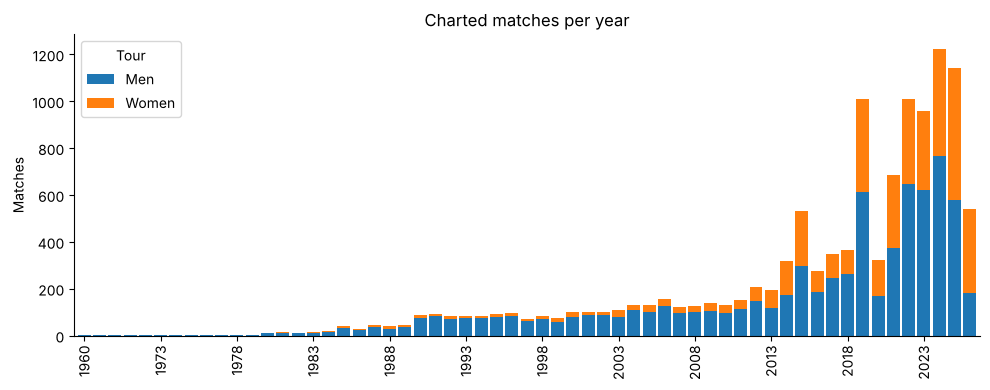

In [4]:
fig, ax = plt.subplots()
(matches.groupby(["Year", "Tour"]).size().unstack(fill_value=0)
        .plot(kind="bar", stacked=True, ax=ax, width=0.85))
ax.set_title("Charted matches per year")
ax.set_xlabel("")
ax.set_ylabel("Matches")
ax.set_xticks(ax.get_xticks()[::5])
plt.tight_layout()

About 80% of the matches are from 2010 onwards; the project started in 2013 and contributors have also charted older matches from video, back to 1960.

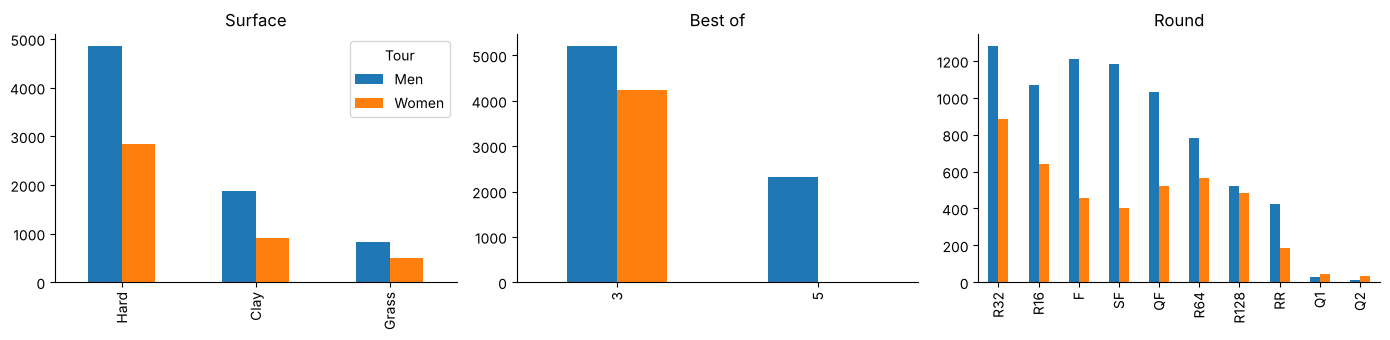

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, column in zip(axes, ["Surface", "Best of", "Round"]):
    counts = (matches.groupby([column, "Tour"]).size()
                     .unstack(fill_value=0))
    counts = counts.loc[counts.sum(axis=1).sort_values(ascending=False)
                        .index[:10]]
    counts.plot(kind="bar", ax=ax, legend=ax is axes[0])
    ax.set_title(column)
    ax.set_xlabel("")
plt.tight_layout()

In [6]:
players = pd.concat([
    matches[["Tour", "Player 1", "Pl 1 hand"]].set_axis(
        ["Tour", "Player", "Hand"], axis=1),
    matches[["Tour", "Player 2", "Pl 2 hand"]].set_axis(
        ["Tour", "Player", "Hand"], axis=1),
])
summary = players.groupby("Tour").agg(
    players=("Player", "nunique"),
    player_appearances=("Player", "size"))
summary["left_handed_share"] = (players.assign(L=players["Hand"] == "L")
                                       .groupby("Tour")["L"].mean())
summary

,players,player_appearances,left_handed_share
Tour,,,
Men,1002,15128,0.110524
Women,737,8490,0.094346


In [7]:
for tour, group in players.groupby("Tour"):
    print(f"{tour}: most charted players")
    print(group["Player"].value_counts().head(10).to_string(), "\n")

Men: most charted players
Player
Roger Federer      723
Novak Djokovic     553
Rafael Nadal       425
Hubert Hurkacz     320
Jannik Sinner      298
Daniil Medvedev    286
Andy Murray        257
Pete Sampras       237
Carlos Alcaraz     222
Andre Agassi       215 

Women: most charted players
Player
Iga Swiatek           237
Bianca Andreescu      196
Elina Svitolina       155
Caroline Wozniacki    155
Serena Williams       146
Elena Rybakina        137
Mirra Andreeva        132
Kiki Bertens          121
Maria Sharapova       118
Coco Gauff            115 



Coverage is very uneven: the most famous players have hundreds of charted matches, while most players have only a few. Any per-player segmentation needs a minimum number of matches per player.

Men: 1002 players; 251 with 10+ matches, 119 with 30+, median 2
Women: 737 players; 199 with 10+ matches, 78 with 30+, median 3


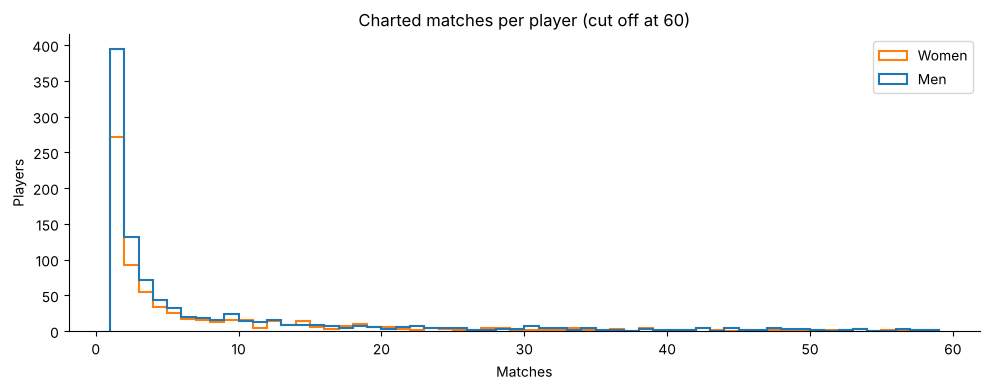

In [8]:
per_player = players.groupby(["Tour", "Player"]).size()
for tour in ("Men", "Women"):
    counts = per_player[tour]
    print(f"{tour}: {len(counts)} players; "
          f"{(counts >= 10).sum()} with 10+ matches, "
          f"{(counts >= 30).sum()} with 30+, median {counts.median():.0f}")

fig, ax = plt.subplots()
ax.hist([per_player["Men"], per_player["Women"]], bins=range(1, 60),
        label=["Men", "Women"], histtype="step", linewidth=1.5)
ax.set_title("Charted matches per player (cut off at 60)")
ax.set_xlabel("Matches")
ax.set_ylabel("Players")
ax.legend()
plt.tight_layout()

In [9]:
print("Top tournaments:")
print(matches["Tournament"].value_counts().head(10).to_string())
print("\nMatches charted by the most active contributors:")
print(matches["Charted by"].value_counts().head(10).to_string())

Top tournaments:
Tournament
Australian Open         1037
US Open                  925
Wimbledon                798
Roland Garros            717
Indian Wells Masters     337
Miami Masters            280
Monte Carlo Masters      237
Tour Finals              234
Rome Masters             230
Paris Masters            229

Matches charted by the most active contributors:
Charted by
Zindaras       1893
Edo            1820
Isaac          1436
BG             1064
Ludo            901
Carrie          729
Lowell          599
chsv            442
KleineBiere     372
tsitsi          208


## 2. Points

One row per point. The useful columns:

| Column | Meaning |
|---|---|
| `Pt` | Point number within the match |
| `Set1`, `Set2`, `Gm1`, `Gm2`, `Pts` | Score before the point (sets, games, points) |
| `Svr` | Server: 1 or 2 (as in the matches file) |
| `1st`, `2nd` | The point in charting notation, for the first serve and (if it was a fault) the second serve |
| `PtWinner` | Who won the point: 1 or 2 |

The notation is the user-entered data, and the rest is derived from it.

In [10]:
points = pd.concat(
    [read(os.path.basename(f)).assign(Tour="Men" if "-m-" in f else "Women")
     for f in sorted(glob.glob(os.path.join(DATA, "charting-*-points-*.csv")))],
    ignore_index=True)
points = points[points["match_id"].isin(matches["match_id"])]
print(f"{len(points):,} points from {points['match_id'].nunique():,} matches")
points.head()

1,876,465 points from 11,776 matches


,match_id,Pt,Set1,Set2,Gm1,Gm2,Pts,Gm#,TbSet,Svr,1st,2nd,Notes,PtWinner,Tour
0,20191124-M-Davis_Cup_Finals-F-Rafael_Nadal-Den...,1,0,0,0.0,0.0,0-0,1.0,True,1,4n,4b1b1b3n@,NaN,1,Men
1,20191124-M-Davis_Cup_Finals-F-Rafael_Nadal-Den...,2,0,0,0.0,0.0,15-0,1.0,True,1,5n,5f28f2b1b1b2f3f3d@,NaN,1,Men
2,20191124-M-Davis_Cup_Finals-F-Rafael_Nadal-Den...,3,0,0,0.0,0.0,30-0,1.0,True,1,4C,NaN,NaN,1,Men
3,20191124-M-Davis_Cup_Finals-F-Rafael_Nadal-Den...,4,0,0,0.0,0.0,40-0,1.0,True,1,4r2d#,NaN,NaN,1,Men
4,20191124-M-Davis_Cup_Finals-F-Rafael_Nadal-Den...,5,0,0,1.0,0.0,0-0,2.0,True,2,5d,c4b1b1d!@,NaN,1,Men


count    11776.0
mean       159.0
std         62.0
min         14.0
25%        113.0
50%        144.0
75%        192.0
max        980.0


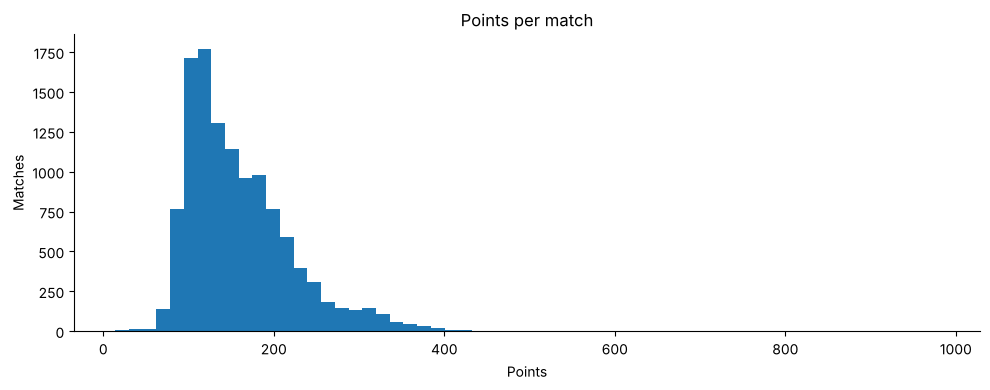

In [11]:
per_match = points.groupby("match_id").size()
print(per_match.describe().round(0).to_string())
fig, ax = plt.subplots()
ax.hist(per_match, bins=60)
ax.set_title("Points per match")
ax.set_xlabel("Points")
ax.set_ylabel("Matches")
plt.tight_layout()

### Reading the notation

Each point is a string, one character (or a few) per shot:

- **Serve**: `4` wide, `5` body, `6` down the T (`0` unknown). A fault is a
  serve followed by an error letter: `n` net, `w` wide, `d` deep, `x` wide
  and deep, `g` foot fault. A `c` before it marks a let.
- **Shots**: `f` forehand, `b` backhand, `r`/`s` forehand/backhand slice,
  `v`/`z` volleys, `o`/`p` overheads, `u`/`y` drop shots, `l`/`m` lobs,
  `h`/`i` half-volleys, `j`/`k` swinging volleys, `t` trick shot, `q`
  unknown.
- **Direction** (after a shot): `1` to a right-hander's forehand side, `2`
  down the middle, `3` to the backhand side. **Return depth**: `7` short,
  `8` middle, `9` deep.
- **How the point ended**: `*` winner (an ace if it comes straight after
  the serve), `#` forced error, `@` unforced error, with the error type
  (`n`, `w`, `d`, `x`) before it.
- `+` approach shot, `-`/`=` at the net / on the baseline, `;` net cord.
- `S`/`R` alone: the point went to the server/returner but wasn't charted
  shot by shot.

For example `6f29b3b1n@` is: serve down the T, forehand return deep down the
middle, backhand to the backhand side, backhand to the forehand side, then
an unforced error into the net.

In [12]:
print(points["1st"].sample(10, random_state=0).to_string())

732483                                            4f1d#
1235177                          6b28b3s2s+1f1v2b-3z1w#
1423354                                           4f3n#
1685971    5b19f38f28f28f39b28f18f19f39b39b28f29f27f18*
20867                                  6s28f2b2b3b3s1n#
1668234                                              4*
1426899                                              6n
661937                               4f28f+38s2z38m39w#
992611                                               6d
226972                                       6s38y2f-1*


## 3. Shots and rallies

Parse each point into a few columns: serve direction, whether the first serve went in, rally length and how the point ended.

In [13]:
SHOTS = set("fbrsvzopuylmhijktq")
SERVES = {"4": "Wide", "5": "Body", "6": "T", "0": "Unknown"}
FAULTS = set("nwdxge!")


def is_fault(text):
    """A serve that is just a direction plus an error code is a fault."""
    text = str(text).lstrip("c")
    return len(text) >= 2 and text[0] in SERVES and set(text[1:]) <= FAULTS


def parse(row):
    first, second = row["1st"], row["2nd"]
    if pd.isna(first) or first[:1] in ("S", "R", "P", "Q"):
        return None  # point not charted shot by shot
    first_in = not is_fault(first)
    played = first if first_in else second
    if pd.isna(played):
        return None
    played = played.lstrip("c")
    if not played:
        return None  # only lets recorded
    if not first_in and is_fault(played):
        return dict(serve=SERVES.get(played[0]), first_in=False,
                    shots=1, ending="Double fault", shot_types="")
    shot_types = "".join(ch for ch in played[1:] if ch in SHOTS)
    shots = 1 + len(shot_types)  # the serve plus every other shot
    if played.endswith("*"):
        ending = "Ace" if shots == 1 else "Winner"
    elif played.endswith("#"):
        ending = "Unreturned serve" if shots == 1 else "Forced error"
    elif played.endswith("@"):
        ending = "Unforced error"
    else:
        ending = "Unknown"
    return dict(serve=SERVES.get(played[0], "Unknown"), first_in=first_in,
                shots=shots, ending=ending, shot_types=shot_types)


parsed = pd.DataFrame(
    [parse(r) or {} for r in points[["1st", "2nd"]].to_dict("records")],
    index=points.index)
points = points.join(parsed)
charted = points.dropna(subset=["shots"]).copy()
charted["shots"] = charted["shots"].astype(int)
charted["first_in"] = charted["first_in"].astype(bool)
charted = charted.merge(matches[["match_id", "Surface", "Year"]],
                        on="match_id")
print(f"Parsed {len(charted):,} of {len(points):,} points "
      f"({len(charted) / len(points):.1%})")
charted[["1st", "2nd", "serve", "first_in", "shots", "ending"]].head(10)

Parsed 1,859,762 of 1,876,465 points (99.1%)


,1st,2nd,serve,first_in,shots,ending
0,4n,4b1b1b3n@,Wide,False,4,Unforced error
1,5n,5f28f2b1b1b2f3f3d@,Body,False,8,Unforced error
2,4C,NaN,Wide,True,1,Unknown
3,4r2d#,NaN,Wide,True,2,Forced error
4,5d,c4b1b1d!@,Wide,False,3,Unforced error
5,4n,4f38f2b1b1b1b1w@,Wide,False,7,Unforced error
6,6f#,NaN,T,True,2,Forced error
7,4f38f+3f1i^1i3n#,NaN,Wide,True,6,Forced error
8,4w,6f17f3f3f3n#,T,False,5,Forced error
9,4r17b1m3o3*,NaN,Wide,True,5,Winner


In [14]:
charted["server_won"] = charted["PtWinner"] == charted["Svr"]
serve_stats = charted.groupby("Tour").agg(
    first_serve_in=("first_in", "mean"),
    aces=("ending", lambda e: (e == "Ace").mean()),
    double_faults=("ending", lambda e: (e == "Double fault").mean()),
    server_won=("server_won", "mean"))
print("Share of points (%):")
(serve_stats * 100).round(1)

Share of points (%):


,first_serve_in,aces,double_faults,server_won
Tour,,,,
Men,63.0,8.2,3.3,64.1
Women,62.9,4.1,4.9,57.0


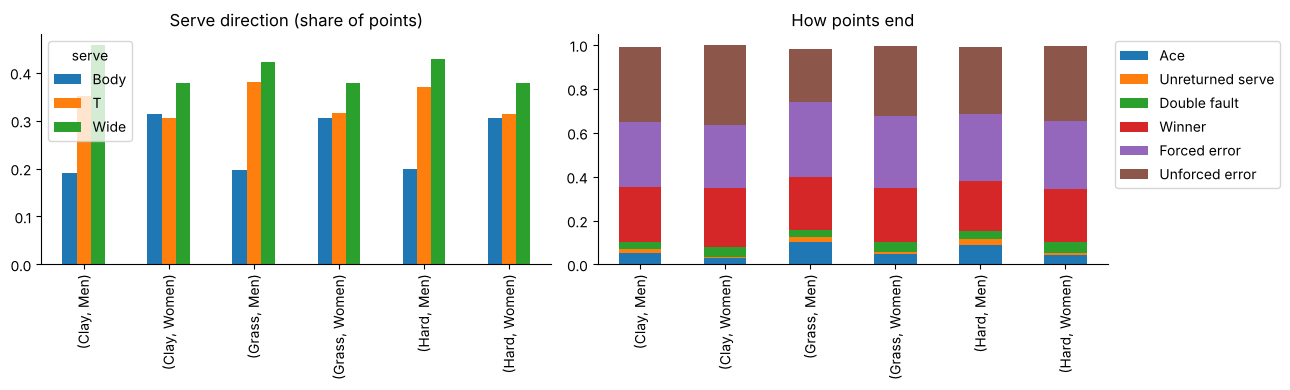

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
(charted.groupby(["Surface", "Tour"])["serve"].value_counts(normalize=True)
        .unstack().drop(columns="Unknown", errors="ignore")
        .plot(kind="bar", ax=axes[0]))
axes[0].set_title("Serve direction (share of points)")
axes[0].set_xlabel("")
(charted.groupby(["Surface", "Tour"])["ending"].value_counts(normalize=True)
        .unstack()[["Ace", "Unreturned serve", "Double fault", "Winner",
                    "Forced error", "Unforced error"]]
        .plot(kind="bar", stacked=True, ax=axes[1]))
axes[1].set_title("How points end")
axes[1].set_xlabel("")
axes[1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout()

Men serve out wide most often (about 43%), then down the T (37%), and at the body least (about 20%). Women spread their serves almost evenly across the three. Aces are most common on grass (10% of men's points) and least common on clay (5%); women hit about half as many aces as men and more double faults.

               mean  50%  75%   max
Tour  Surface                      
Men   Clay      5.2  4.0  7.0  86.0
      Grass     3.8  3.0  5.0  45.0
      Hard      4.6  3.0  6.0  85.0
Women Clay      5.1  4.0  7.0  51.0
      Grass     4.4  3.0  6.0  33.0
      Hard      4.8  4.0  6.0  49.0


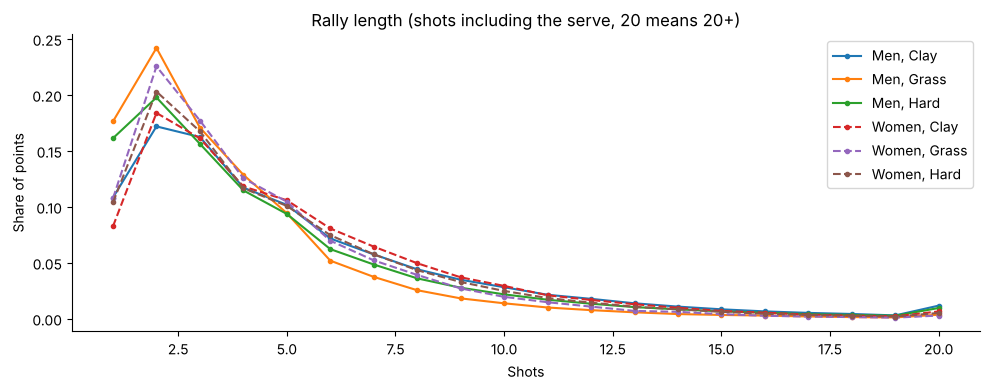

In [16]:
print(charted.groupby(["Tour", "Surface"])["shots"]
             .describe()[["mean", "50%", "75%", "max"]].round(1))
fig, ax = plt.subplots()
for (tour, surface), group in charted.groupby(["Tour", "Surface"]):
    if surface == "Carpet":
        continue
    share = group["shots"].clip(upper=20).value_counts(normalize=True)
    ax.plot(share.sort_index(), marker=".",
            linestyle="-" if tour == "Men" else "--",
            label=f"{tour}, {surface}")
ax.set_title("Rally length (shots including the serve, 20 means 20+)")
ax.set_xlabel("Shots")
ax.set_ylabel("Share of points")
ax.legend()
plt.tight_layout()

Most points are short. The single most common length is 2 shots (the point ends on the return), and about 60% of points are over within 4 shots. Clay rallies are longest and grass rallies shortest, especially for men.

In [17]:
NAMES = {"f": "Forehand", "b": "Backhand", "r": "FH slice", "s": "BH slice",
         "v": "FH volley", "z": "BH volley", "o": "Overhead",
         "p": "BH overhead", "u": "FH drop shot", "y": "BH drop shot",
         "l": "FH lob", "m": "BH lob", "h": "FH half-volley",
         "i": "BH half-volley", "j": "FH swinging volley",
         "k": "BH swinging volley", "t": "Trick shot", "q": "Unknown"}
shot_counts = (charted.groupby("Tour")["shot_types"]
                      .apply(lambda s: pd.Series(list("".join(s)))
                                         .value_counts(normalize=True))
                      .unstack(0).rename(index=NAMES))
print("Share of shots after the serve (%):")
(shot_counts.sort_values("Men", ascending=False) * 100).round(1)

Share of shots after the serve (%):


Tour,Men,Women
Forehand,43.7,45.4
Backhand,35.5,38.6
BH slice,9.7,6.5
FH slice,3.0,3.6
BH volley,1.9,0.7
FH volley,1.8,0.8
BH lob,0.9,1.0
Overhead,0.9,0.6
BH drop shot,0.6,0.7
FH drop shot,0.6,0.4


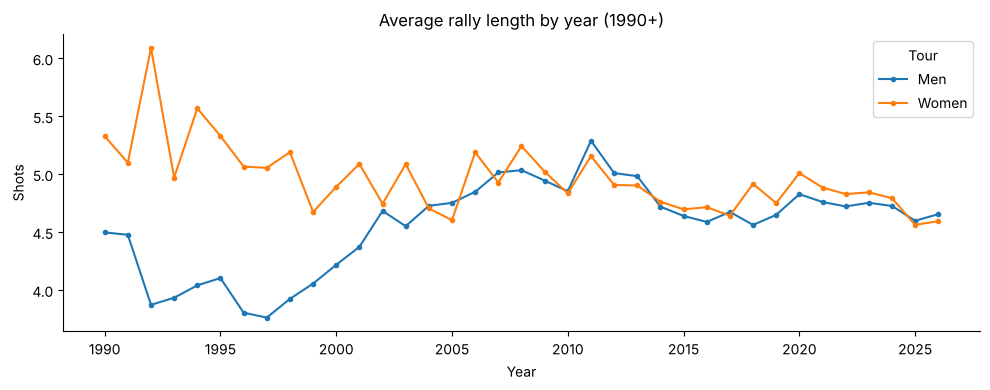

In [18]:
by_year = (charted[charted["Year"] >= 1990]
           .groupby(["Tour", "Year"])["shots"].mean().unstack(0))
by_year.plot(marker=".", title="Average rally length by year (1990+)")
plt.ylabel("Shots")
plt.tight_layout()

## 4. Player stats

The `stats-Overview` files have per-match totals for each player (serve
points, aces, double faults, first serves in and won, break points, winners,
unforced errors). Each match has a `Total` row plus one per set; only the
totals are used here. Rates are worked out per player, over every charted
match, for players with at least 20 charted matches.

In [19]:
overview = pd.concat(
    [read(f"charting-{g}-stats-Overview.csv").assign(Tour=tour)
     for g, tour in (("m", "Men"), ("w", "Women"))],
    ignore_index=True)
overview = overview[(overview["set"] == "Total")
                    & overview["match_id"].isin(matches["match_id"])]
print(overview.shape)
overview.head()

(23600, 21)


,match_id,player,set,serve_pts,aces,dfs,first_in,first_won,second_in,second_won,bk_pts,bp_saved,return_pts,return_pts_won,winners,winners_fh,winners_bh,unforced,unforced_fh,unforced_bh,Tour
0,20260521-M-Roland_Garros-Q3-Jesper_De_Jong-Mic...,Jesper De Jong,Total,80,6,4,48,33,32,13,11,8,61,18,25,13,5,25,15,6,Men
1,20260521-M-Roland_Garros-Q3-Jesper_De_Jong-Mic...,Michael Zheng,Total,61,3,2,34,27,27,16,3,3,80,34,28,23,2,21,11,8,Men
7,20260517-M-Rome_Masters-F-Casper_Ruud-Jannik_S...,Casper Ruud,Total,64,3,2,37,24,27,13,5,2,55,16,22,13,6,22,11,9,Men
8,20260517-M-Rome_Masters-F-Casper_Ruud-Jannik_S...,Jannik Sinner,Total,55,2,0,35,29,20,10,2,1,64,27,27,15,10,18,9,9,Men
12,20260511-M-Rome_Masters-R16-Rafael_Jodar-Learn...,Rafael Jodar,Total,50,0,0,33,23,17,11,1,0,52,26,10,5,5,19,11,8,Men


In [20]:
totals = overview.groupby(["Tour", "player"]).agg(
    matches=("match_id", "nunique"),
    **{c: (c, "sum") for c in ["serve_pts", "aces", "dfs", "first_in",
                               "first_won", "second_in", "second_won",
                               "return_pts", "return_pts_won", "winners",
                               "unforced"]})
totals = totals[totals["matches"] >= 20].copy()
all_points = totals["serve_pts"] + totals["return_pts"]
rates = pd.DataFrame({
    "matches": totals["matches"],
    "ace_rate": totals["aces"] / totals["serve_pts"],
    "df_rate": totals["dfs"] / totals["serve_pts"],
    "first_in": totals["first_in"] / totals["serve_pts"],
    "first_won": totals["first_won"] / totals["first_in"],
    "second_won": totals["second_won"] / totals["second_in"],
    "return_won": totals["return_pts_won"] / totals["return_pts"],
    "winners_per_pt": totals["winners"] / all_points,
    "unforced_per_pt": totals["unforced"] / all_points,
})
print(rates.groupby("Tour").size().to_string())
rates.describe().round(3)

Tour
Men      158
Women    110


,matches,ace_rate,df_rate,first_in,first_won,second_won,return_won,winners_per_pt,unforced_per_pt
count,268.000,268.000,268.000,268.000,268.000,268.000,268.000,268.000,268.000
mean,67.011,0.065,0.042,0.622,0.685,0.484,0.384,0.165,0.184
std,75.454,0.040,0.016,0.041,0.056,0.038,0.048,0.030,0.026
min,20.000,0.001,0.012,0.514,0.512,0.347,0.257,0.092,0.119
25%,29.000,0.037,0.029,0.596,0.646,0.457,0.347,0.145,0.166
50%,42.500,0.057,0.039,0.621,0.684,0.489,0.382,0.162,0.184
75%,74.250,0.086,0.050,0.649,0.727,0.512,0.423,0.182,0.202
max,722.000,0.221,0.105,0.778,0.821,0.564,0.489,0.283,0.271


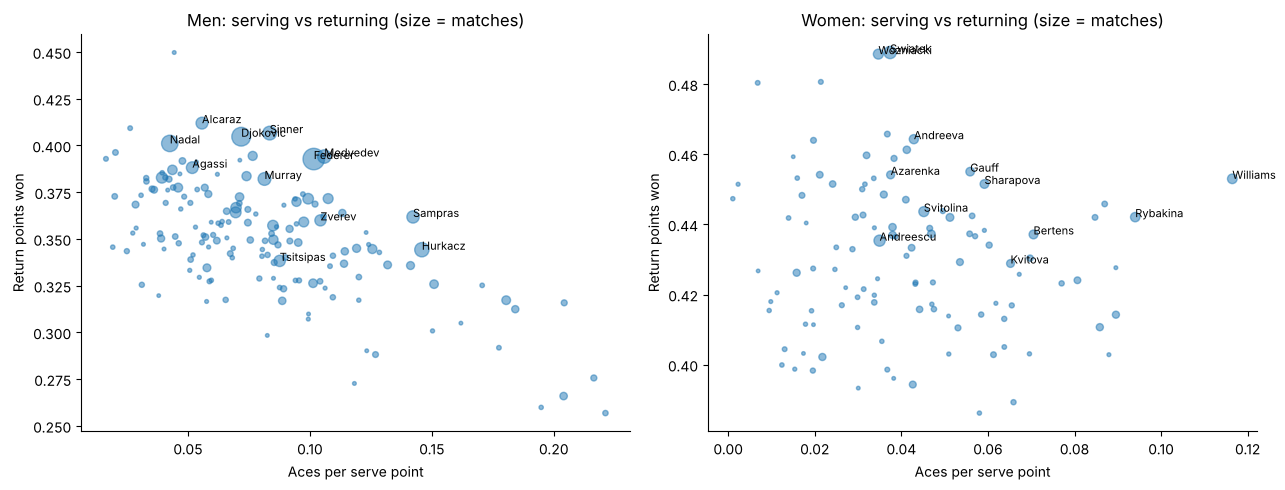

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (tour, group) in zip(axes, rates.groupby("Tour")):
    group = group.droplevel("Tour")
    ax.scatter(group["ace_rate"], group["return_won"],
               s=group["matches"] / 3, alpha=0.5)
    for name in group["matches"].nlargest(12).index:
        ax.annotate(name.split()[-1], (group.loc[name, "ace_rate"],
                                       group.loc[name, "return_won"]),
                    fontsize=8)
    ax.set_title(f"{tour}: serving vs returning (size = matches)")
    ax.set_xlabel("Aces per serve point")
    ax.set_ylabel("Return points won")
plt.tight_layout()

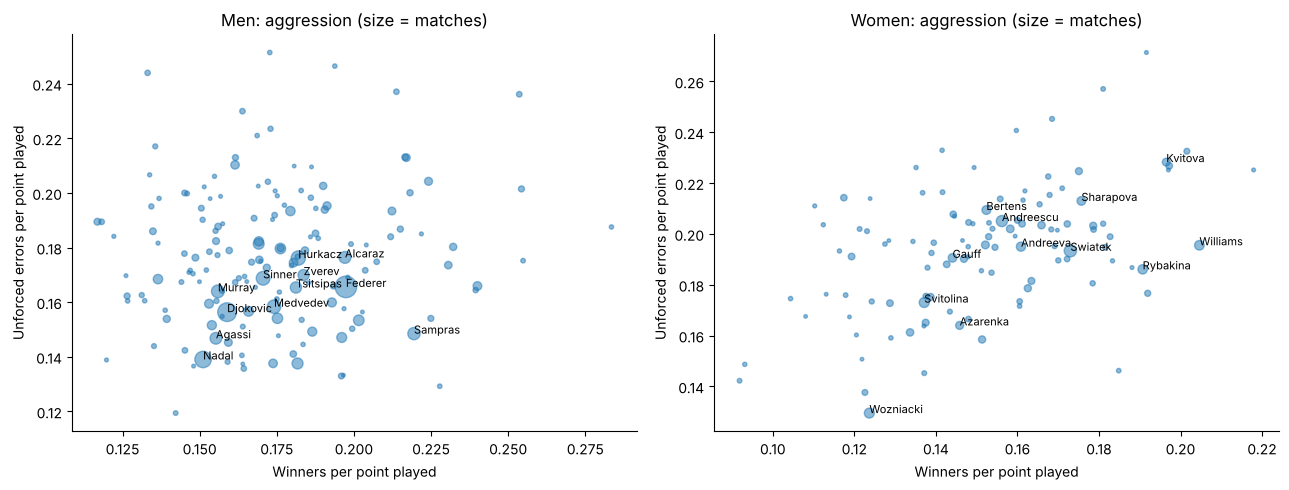

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (tour, group) in zip(axes, rates.groupby("Tour")):
    group = group.droplevel("Tour")
    ax.scatter(group["winners_per_pt"], group["unforced_per_pt"],
               s=group["matches"] / 3, alpha=0.5)
    for name in group["matches"].nlargest(12).index:
        ax.annotate(name.split()[-1], (group.loc[name, "winners_per_pt"],
                                       group.loc[name, "unforced_per_pt"]),
                    fontsize=8)
    ax.set_title(f"{tour}: aggression (size = matches)")
    ax.set_xlabel("Winners per point played")
    ax.set_ylabel("Unforced errors per point played")
plt.tight_layout()

These two views already separate styles: big servers sit to the right of the first plot and strong returners near the top, while the second plot splits high-risk shot-makers from steadier players.

In [23]:
rates.drop(columns="matches").corr().round(2)

,ace_rate,df_rate,first_in,first_won,second_won,return_won,winners_per_pt,unforced_per_pt
ace_rate,1.00,0.01,-0.27,0.88,0.45,-0.66,0.80,-0.12
df_rate,0.01,1.00,-0.30,-0.09,-0.54,0.30,0.09,0.44
first_in,-0.27,-0.30,1.00,-0.41,-0.12,0.12,-0.27,-0.15
first_won,0.88,-0.09,-0.41,1.00,0.64,-0.63,0.76,-0.23
second_won,0.45,-0.54,-0.12,0.64,1.00,-0.48,0.44,-0.37
return_won,-0.66,0.30,0.12,-0.63,-0.48,1.00,-0.48,0.18
winners_per_pt,0.80,0.09,-0.27,0.76,0.44,-0.48,1.00,0.09
unforced_per_pt,-0.12,0.44,-0.15,-0.23,-0.37,0.18,0.09,1.00


## 5. Data quality

Things to handle before using the data for modelling.

In [24]:
print(f"Malformed match rows dropped: {len(bad_matches)}")
print(bad_matches[["match_id", "Date", "Surface", "Best of"]]
      .head().to_string(), "\n")

no_points = set(matches["match_id"]) - set(points["match_id"])
print(f"Matches with no points: {len(no_points)}")

uncharted = points["shots"].isna()
print(f"Points not charted shot by shot (S/R codes etc.): "
      f"{uncharted.sum():,} ({uncharted.mean():.1%})")
print(f"Points whose ending could not be read: "
      f"{(charted['ending'] == 'Unknown').sum():,}")

mismatch = points.groupby("match_id")["Pt"].agg(["size", "max"])
print(f"Matches where point numbers skip or repeat: "
      f"{(mismatch['size'] != mismatch['max']).sum()}")

pairs = matches.groupby("match_id").size()
print(f"Duplicate match_ids: {(pairs > 1).sum()}")

Malformed match rows dropped: 21
                                                                           match_id       Date             Surface   Best of
905            20240915-M-Davis_Cup_World_Group-RR-Tallon_Griekspoor-Flavio_Cobolli 2024-09-15  Eva Asderaki-Moore         1
906   20240915-M-Davis_Cup_World_Group-RR-Botic_Van_De_Zandschulp-Matteo_Berrettini        NaT                   3  Zindaras
9303              20221111-W-BJK_Cup_Finals-RR-Danielle_Collins-Marketa_Vondrousova 2022-11-11  Eva Asderaki-Moore         1
9304                     20221111-W-BJK_Cup_Finals-RR-Coco_Gauff-Katerina_Siniakova        NaT                   1       NaN
9305            20221111-W-BJK_Cup_Finals-RR-Alize_Cornet-Lesley_Pattinama_Kerkhove        NaT                   1       NaN 



Matches with no points: 33
Points not charted shot by shot (S/R codes etc.): 16,703 (0.9%)
Points whose ending could not be read: 17,167


Matches where point numbers skip or repeat: 14
Duplicate match_ids: 0


## Summary

- **About 11,800 matches** (7,600 men's, 4,200 women's) and **1.9 million
  points** are charted shot by shot. Most matches are from 2010 onwards, on
  hard courts, at the big tournaments.
- **Coverage is uneven.** Stars like Federer, Djokovic and Nadal have
  hundreds of matches while most players have only a few, so player-level
  work needs a minimum match count (20+ leaves a few hundred players).
- **The notation holds a lot of detail**: serve direction, every shot type,
  direction and depth, and how each point ended. Parsing it gives rally
  length, shot mix and point endings for every point.
- **Surface matters**: grass means more aces and shorter rallies, clay the
  opposite. Men and women also differ (women hit about half as many aces and
  win fewer service points), so features should be compared within a surface (or adjusted
  for it).
- **The data is mostly clean**, apart from a few malformed match rows,
  some points recorded only as `S`/`R`, and a few matches with gaps in their
  point numbers.

### Ideas for segmentation

- **Players by style**: cluster players on per-player rates like the ones in
  section 4 (ace rate, return points won, winners and unforced errors per
  point), plus shot mix from the notation (slice share, net approaches,
  drop shots) and rally length, compared within each surface.
- **Points by pattern**: cluster points on serve direction, rally length,
  shot sequence and ending (e.g. serve + 1 forehand, long baseline rallies,
  net rushes).
- **Matches by phase**: split each match into stretches where a player's
  serve and rally stats change, e.g. momentum swings.